In [ ]:
For the UN dataset: 

The data for the UN study on fertility contains GDP and fertility rates for
193 nations. It also contains log transforms for both variables. Generated two 
scatter plots of PPgdp vs Fertility, one using linear scaling for both 
variables and the other using log scaling for both variables.    

Performed linear regression using both log and linear transformations of the 
data.  

Determined which regression exhibits a better fit (log or linear)? Used the ANOVA summary 
to support my reasoning.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pandas.plotting import scatter_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, FactorAnalysis

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

In [2]:
un_df = pd.read_csv("HW4_UN1.csv")

print("UN dataset dimensions:", un_df.shape)
display(un_df.head())

UN dataset dimensions: (193, 4)


,Fertility,PPgdp,LogFertility,LogPPgdp
0,6.80,98,1.916923,4.584967
1,2.28,1317,0.824175,7.183112
2,2.80,1784,1.029619,7.486613
3,7.20,739,1.974081,6.605298
4,2.44,7163,0.891998,8.876684


In [ ]:
Q7: Linear and Log-scale Scatter plots

In [3]:
print(un_df.columns.tolist())

['Fertility', 'PPgdp', 'LogFertility', 'LogPPgdp']


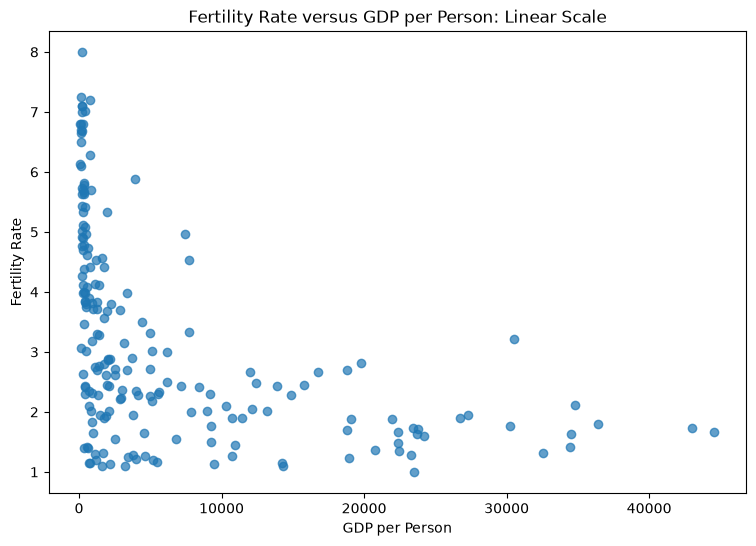

In [4]:
# Linear-scale Scatter plot

plt.figure(figsize=(9, 6))

plt.scatter(
    un_df["PPgdp"],
    un_df["Fertility"],
    alpha=0.70
)

plt.xlabel("GDP per Person")
plt.ylabel("Fertility Rate")
plt.title("Fertility Rate versus GDP per Person: Linear Scale")

plt.show()

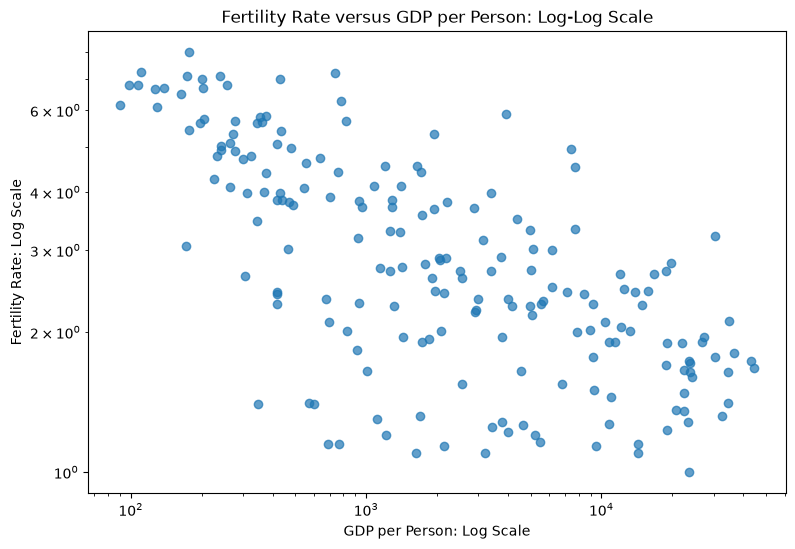

In [5]:
# Log-scale scatter plot using log axes

plt.figure(figsize=(9, 6))

plt.scatter(
    un_df["PPgdp"],
    un_df["Fertility"],
    alpha=0.70
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("GDP per Person: Log Scale")
plt.ylabel("Fertility Rate: Log Scale")
plt.title("Fertility Rate versus GDP per Person: Log-Log Scale")

plt.show()

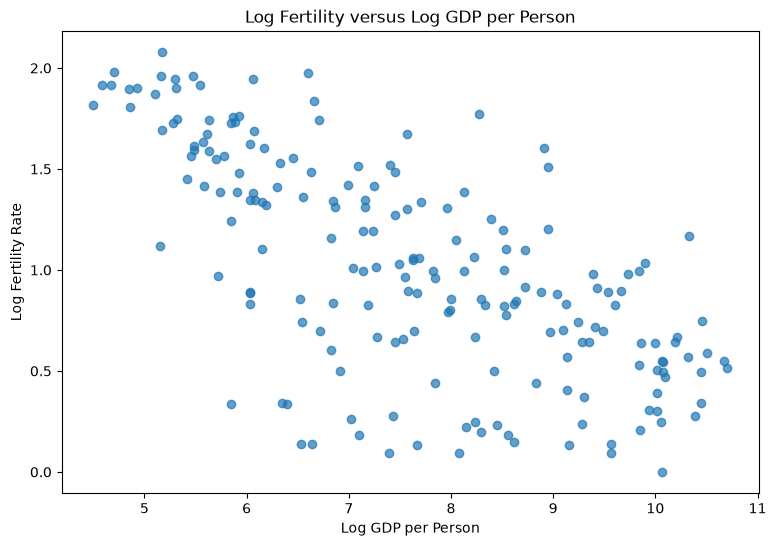

In [6]:
# Alternative plot using the transformed columns

plt.figure(figsize=(9, 6))

plt.scatter(
    un_df["LogPPgdp"],
    un_df["LogFertility"],
    alpha=0.70
)

plt.xlabel("Log GDP per Person")
plt.ylabel("Log Fertility Rate")
plt.title("Log Fertility versus Log GDP per Person")

plt.show()

In [7]:
# Linear regression using original variables

un_linear_model = smf.ols(
    formula="Fertility ~ PPgdp",
    data=un_df
).fit()

In [8]:
# Linear model summary

print(un_linear_model.summary())

                            OLS Regression Results                            
Dep. Variable:              Fertility   R-squared:                       0.215
Model:                            OLS   Adj. R-squared:                  0.211
Method:                 Least Squares   F-statistic:                     52.22
Date:                Sun, 19 Jul 2026   Prob (F-statistic):           1.15e-11
Time:                        21:38:53   Log-Likelihood:                -354.41
No. Observations:                 193   AIC:                             712.8
Df Residuals:                     191   BIC:                             719.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      3.7333      0.133     28.040      0.0

In [9]:
# Linear model ANOVA

un_linear_anova = anova_lm(
    un_linear_model
)

display(un_linear_anova)

,df,sum_sq,mean_sq,F,PR(>F)
PPgdp,1.0,121.588365,121.588365,52.222198,1.154603e-11
Residual,191.0,444.703183,2.328289,NaN,NaN


In [10]:
# Linear regression equation

linear_intercept = un_linear_model.params["Intercept"]
linear_slope = un_linear_model.params["PPgdp"]

print(
    "Linear regression equation:"
)

print(
    f"Fertility = {linear_intercept:.4f} "
    f"+ ({linear_slope:.8f} × PPgdp)"
)

Linear regression equation:
Fertility = 3.7333 + (-0.00008486 × PPgdp)


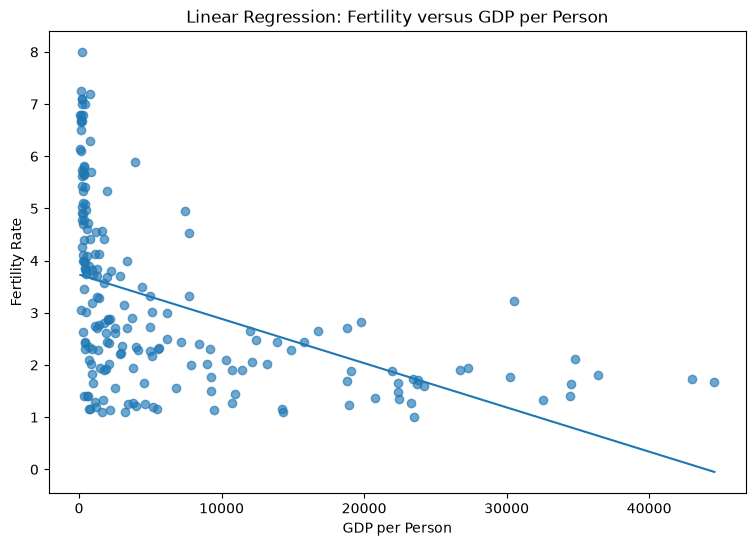

In [11]:
# Linear regression plot

un_sorted_linear = un_df.sort_values("PPgdp")

plt.figure(figsize=(9, 6))

plt.scatter(
    un_df["PPgdp"],
    un_df["Fertility"],
    alpha=0.65
)

plt.plot(
    un_sorted_linear["PPgdp"],
    un_linear_model.predict(
        un_sorted_linear
    )
)

plt.xlabel("GDP per Person")
plt.ylabel("Fertility Rate")
plt.title("Linear Regression: Fertility versus GDP per Person")

plt.show()

In [12]:
# Log regression

un_log_model = smf.ols(
    formula="LogFertility ~ LogPPgdp",
    data=un_df
).fit()

In [13]:
# Log model summary

print(un_log_model.summary())

                            OLS Regression Results                            
Dep. Variable:           LogFertility   R-squared:                       0.459
Model:                            OLS   Adj. R-squared:                  0.456
Method:                 Least Squares   F-statistic:                     162.1
Date:                Sun, 19 Jul 2026   Prob (F-statistic):           2.73e-27
Time:                        21:41:38   Log-Likelihood:                -94.158
No. Observations:                 193   AIC:                             192.3
Df Residuals:                     191   BIC:                             198.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.7032      0.135     19.968      0.0

In [14]:
# Log model ANOVA

un_log_anova = anova_lm(
    un_log_model
)

display(un_log_anova)

,df,sum_sq,mean_sq,F,PR(>F)
LogPPgdp,1.0,25.451244,25.451244,162.145973,2.731002e-27
Residual,191.0,29.980317,0.156965,NaN,NaN


In [15]:
# Log regression equation

log_intercept = un_log_model.params["Intercept"]
log_slope = un_log_model.params["LogPPgdp"]

print(
    "Log-log regression equation:"
)

print(
    f"LogFertility = {log_intercept:.4f} "
    f"+ ({log_slope:.4f} × LogPPgdp)"
)

Log-log regression equation:
LogFertility = 2.7032 + (-0.2212 × LogPPgdp)


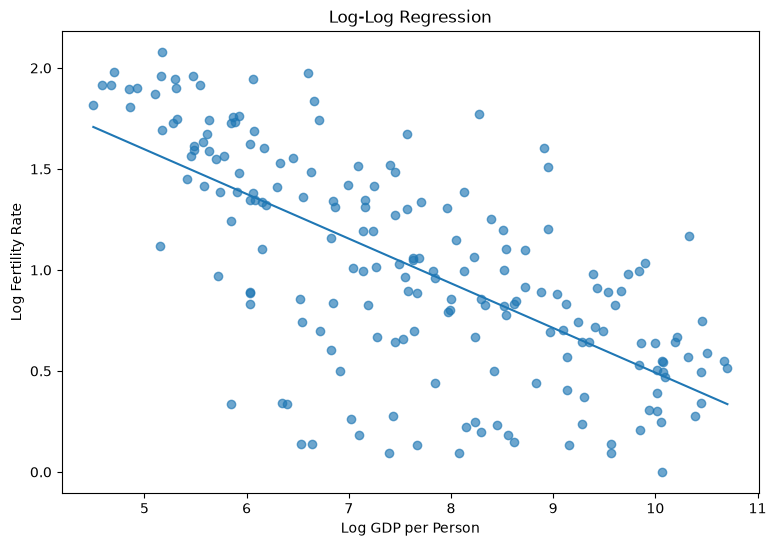

In [16]:
# Log regression plot

un_sorted_log = un_df.sort_values("LogPPgdp")

plt.figure(figsize=(9, 6))

plt.scatter(
    un_df["LogPPgdp"],
    un_df["LogFertility"],
    alpha=0.65
)

plt.plot(
    un_sorted_log["LogPPgdp"],
    un_log_model.predict(
        un_sorted_log
    )
)

plt.xlabel("Log GDP per Person")
plt.ylabel("Log Fertility Rate")
plt.title("Log-Log Regression")

plt.show()

In [ ]:
Comparing the linear and log regressions

In [17]:
un_model_comparison = pd.DataFrame({
    "Model": [
        "Linear Model",
        "Log-Log Model"
    ],
    "R-squared": [
        un_linear_model.rsquared,
        un_log_model.rsquared
    ],
    "Adjusted R-squared": [
        un_linear_model.rsquared_adj,
        un_log_model.rsquared_adj
    ],
    "F Statistic": [
        un_linear_model.fvalue,
        un_log_model.fvalue
    ],
    "F-test p-value": [
        un_linear_model.f_pvalue,
        un_log_model.f_pvalue
    ],
    "AIC": [
        un_linear_model.aic,
        un_log_model.aic
    ]
})

display(un_model_comparison)

,Model,R-squared,Adjusted R-squared,F Statistic,F-test p-value,AIC
0,Linear Model,0.214710,0.210598,52.222198,1.154603e-11,712.810629
1,Log-Log Model,0.459147,0.456315,162.145973,2.731002e-27,192.315493


The log-log regression model provides a substantially better fit than the linear 
regression model. The linear model explains only 21.47% of the variation in 
fertility (R² = 0.2147), while the log-log model explains 45.91% (R² = 0.4591), 
more than doubling the amount of variation accounted for by the model. The 
adjusted R² also improves from 0.2106 to 0.4563, indicating that the improvement 
is not simply due to model complexity.

The ANOVA results further support the log-log model. Its F-statistic is 162.15, 
compared to 52.22 for the linear model, and both models have statistically 
significant p-values (p < 0.001). The much larger F-statistic indicates that the 
relationship between GDP and fertility is captured much more effectively after 
applying the logarithmic transformation. Therefore, the log-log regression is the 
preferred model because it provides a stronger overall fit and better explains 
the relationship between GDP per person and fertility rates across countries.